In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
from windrose import WindroseAxes
import foxes
import foxes.variables as FV
from pathlib import Path
import importlib, nowake_analysis as ta
importlib.reload(ta)



/home/janos/miniforge3/envs/wind/lib/python3.14/site-packages/foxes/core/engine.py:4: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


<module 'nowake_analysis' from '/home/janos/python-wind-project/nowake_analysis.py'>

In [2]:
df = pd.read_csv('reanalysis/reanalysis_2006.csv')
print(df.head())

             Date_time  WS100  WD100
0  2006-01-01 00:00:00  8.515  243.1
1  2006-01-01 01:00:00  8.379  246.2
2  2006-01-01 02:00:00  7.772  245.6
3  2006-01-01 03:00:00  7.852  241.6
4  2006-01-01 04:00:00  8.319  239.5


In [3]:
dt_index = pd.to_datetime(df["Date_time"], utc=True)
df = df.set_index(dt_index)
df.index.name = "Date_time"
df = df.sort_index()
df = df.drop(columns=["Date_time"])
print(df.head())

                           WS100  WD100
Date_time                              
2006-01-01 00:00:00+00:00  8.515  243.1
2006-01-01 01:00:00+00:00  8.379  246.2
2006-01-01 02:00:00+00:00  7.772  245.6
2006-01-01 03:00:00+00:00  7.852  241.6
2006-01-01 04:00:00+00:00  8.319  239.5


In [4]:
print(len(df) - (365*24))

0


In [5]:
print(np.sum(df.index.duplicated()))

0


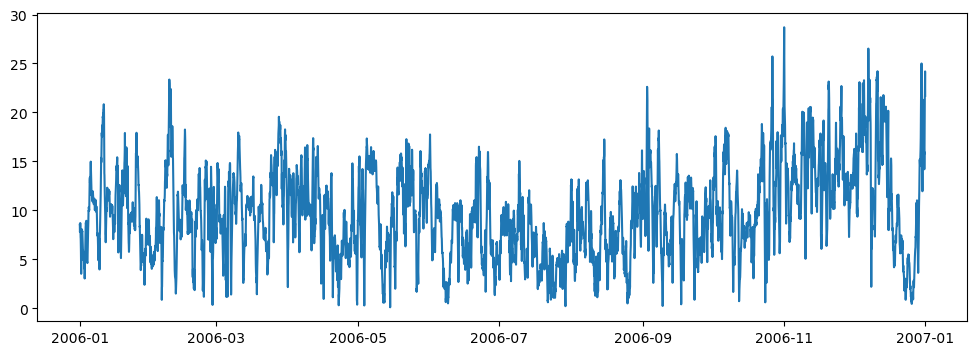

In [6]:
plt.figure(figsize=(12,4))
plt.plot(df['WS100'])
plt.show()

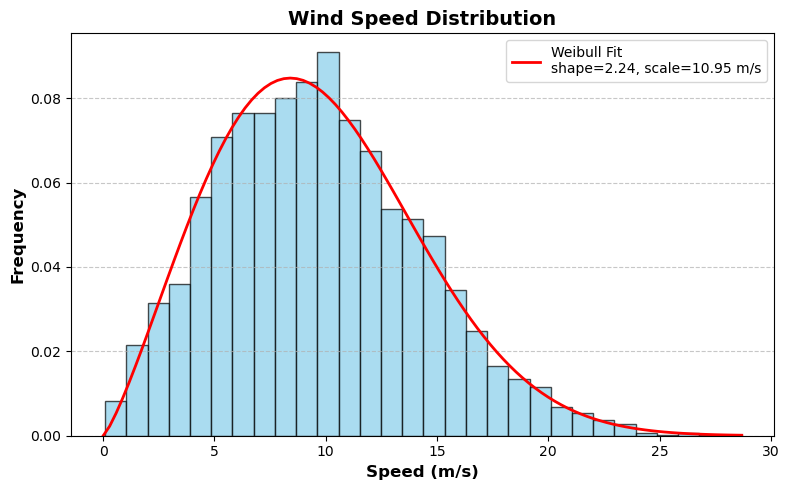

In [7]:
shape, loc, scale = stats.weibull_min.fit(df['WS100'], floc=0)

plt.figure(figsize=(8, 5))
plt.hist(df['WS100'], bins=30, density=True, color='skyblue', edgecolor='black', alpha=0.7)

x = np.linspace(0, max(df['WS100']), 100)
plt.plot(x, stats.weibull_min.pdf(x, shape, loc, scale), 'r-', lw=2, label=f'Weibull Fit\nshape={shape:.2f}, scale={scale:.2f} m/s')

plt.title('Wind Speed Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Speed (m/s)', fontsize=12, fontweight='bold')
plt.ylabel('Frequency', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Task 3: Yield of the Areas N-10.1/N-10.2 Without External Wake Effects

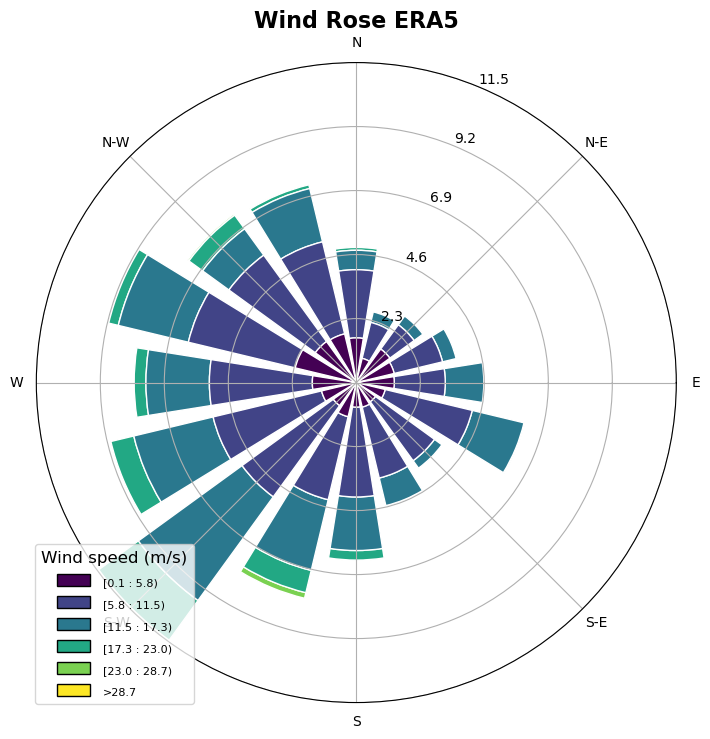

In [8]:
fig = plt.figure(figsize=(8, 8))
ax = WindroseAxes.from_ax(fig=fig)

ax.bar(
    df['WD100'],
    df['WS100'],
    normed=True,
    opening=0.8,
    edgecolor="white"
)

ax.set_legend(title="Wind speed (m/s)", fontsize=12, title_fontsize=12)
ax.set_title("Wind Rose ERA5",fontsize=16, fontweight="bold")
plt.show()

In [9]:
#===============================================================
# Step 1: Load ERA5 Data as States
#===============================================================
latitude = 54.602
longitude = 6.145
states = foxes.input.states.Timeseries(
    data_source = Path("reanalysis/reanalysis_2006.csv"),
    output_vars = [FV.WS, FV.WD, FV.TI, FV.RHO],
    var2col={FV.WS: "WS100", FV.WD: "WD100"},
    fixed_vars={FV.TI: 0.05, FV.RHO: 1.225},  
  # log-law extrapolation to hub height 
    read_pars={"dayfirst": True}
)

#================================================================
# Step 2: Set Up turbine type
#================================================================
mbook = foxes.ModelBook()
mbook.turbine_types["IEA15MW"] = foxes.models.turbine_types.PCtFile(
    Path("./turbine-info/power_curves/IEA-15MW-D240-H150.csv").resolve(strict=True),
    col_ws="ws", 
    col_P="P",
    col_ct="ct",
    D=240.0,
    H=150.0,
    P_nominal=15000,
    P_unit="kW",
    rho=1.225
)
#================================================================
# Step 3-5: Compute farm results
#================================================================
def compute_farm(farm_layout, states, mbook, farm_name):
    """Compute the farm results for a given layout and states.
        Parameters:
        -----------
        farm_layout: str
            Path to the CSV file containing the farm layout (columns: x, y).
        states: foxes.input.states.Timeseries
            The input states containing the meteorological data.
        mbook: foxes.ModelBook
            The model book containing turbine definitions and other models.
        farm_name: str
            A name for the wind farm (used for identification in outputs).
        Returns:
        --------
        results: foxes.output.FarmResults
            The computed results for the wind farm.
        farm: foxes.WindFarm
            The wind farm object containing turbine information and layout.
        algorithm: foxes.algorithms.Downwind
            The algorithm object used for the farm calculation.
    """
    #--------------------------------------------------------------------
    # step 3: Wind Farm Layout
    #--------------------------------------------------------------------
    farm = foxes.WindFarm(name=farm_name)
    
    foxes.input.farm_layout.add_from_file(
        farm,
        farm_layout,
        col_x="x",
        col_y="y",
        turbine_models=["IEA15MW"],
        verbosity=0
    )

    #----------------------------------------------------------------
    # Step 4: Algorithm setup for no wake models
    #----------------------------------------------------------------
    algorithm = foxes.algorithms.Downwind(
        farm,
        states,
        wake_models=[],
        mbook=mbook,
        verbosity=0
    )

    #----------------------------------------------------------------
    # Step 5: Run the foxes
    #----------------------------------------------------------------
    engine = foxes.Engine.new("process", chunk_size_states=500)
    with engine:
        results = algorithm.calc_farm()
    return results



ProcessEngine: Calculating 8760 states for 133 turbines
ProcessEngine: Starting calculation using 3 workers, for 18 states chunks.


  0%|          | 0/18 [00:00<?, ?it/s]

ProcessEngine: Completed all 18 chunks


  YIELD SUMMARY — N-10.1
  Number of turbines      : 133
  Turbine yield (annual)  :
    Min  : 79.94 GWh
    Max  : 79.94 GWh
    Mean : 79.94 GWh
  Total farm yield/year   : 10632.19 GWh
  Mean farm power         : 1213.72 MW
  Rated capacity          : 1995 MW
  Capacity factor         : 60.8 %



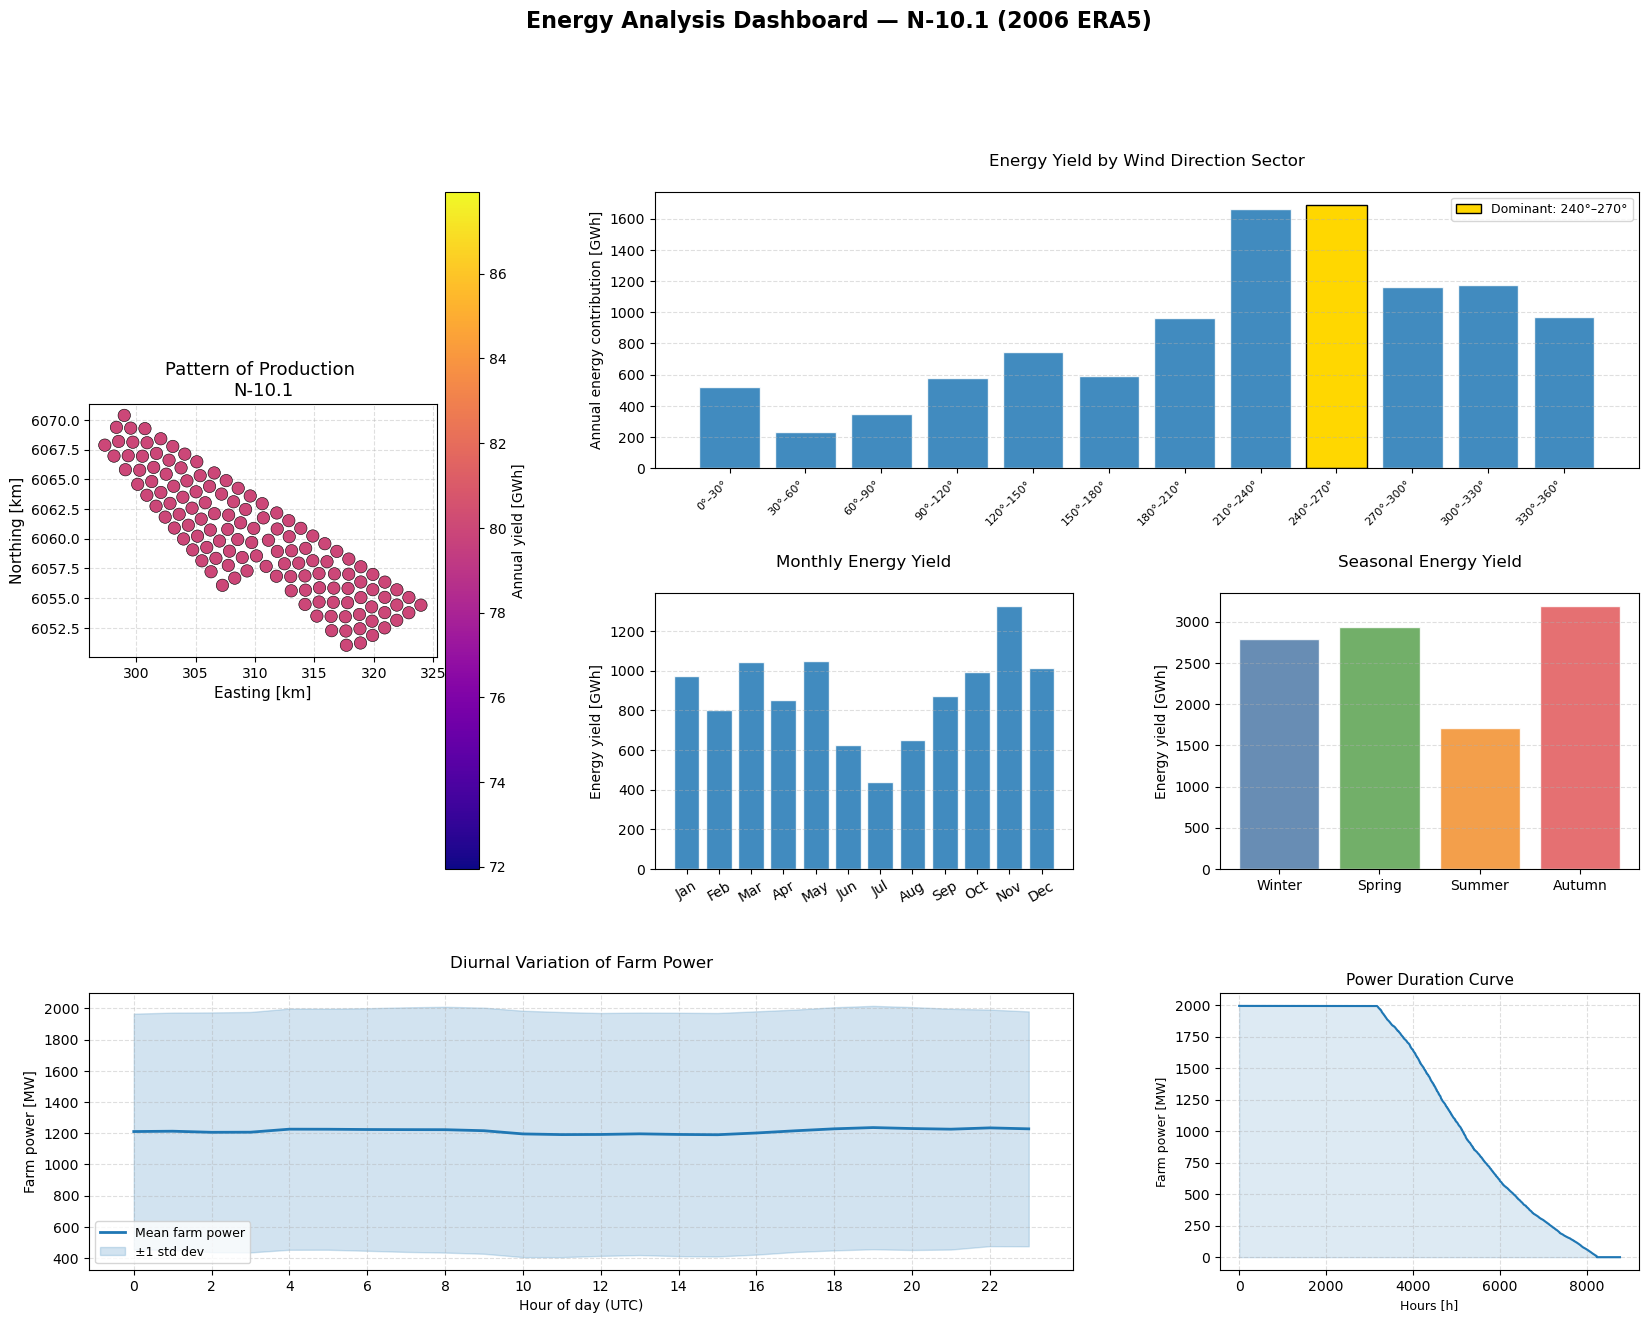

ProcessEngine: Calculating 8760 states for 33 turbines
ProcessEngine: Starting calculation using 3 workers, for 18 states chunks.


  0%|          | 0/18 [00:00<?, ?it/s]

ProcessEngine: Completed all 18 chunks


  YIELD SUMMARY — N-10.2
  Number of turbines      : 33
  Turbine yield (annual)  :
    Min  : 79.94 GWh
    Max  : 79.94 GWh
    Mean : 79.94 GWh
  Total farm yield/year   : 2638.06 GWh
  Mean farm power         : 301.15 MW
  Rated capacity          : 495 MW
  Capacity factor         : 60.8 %



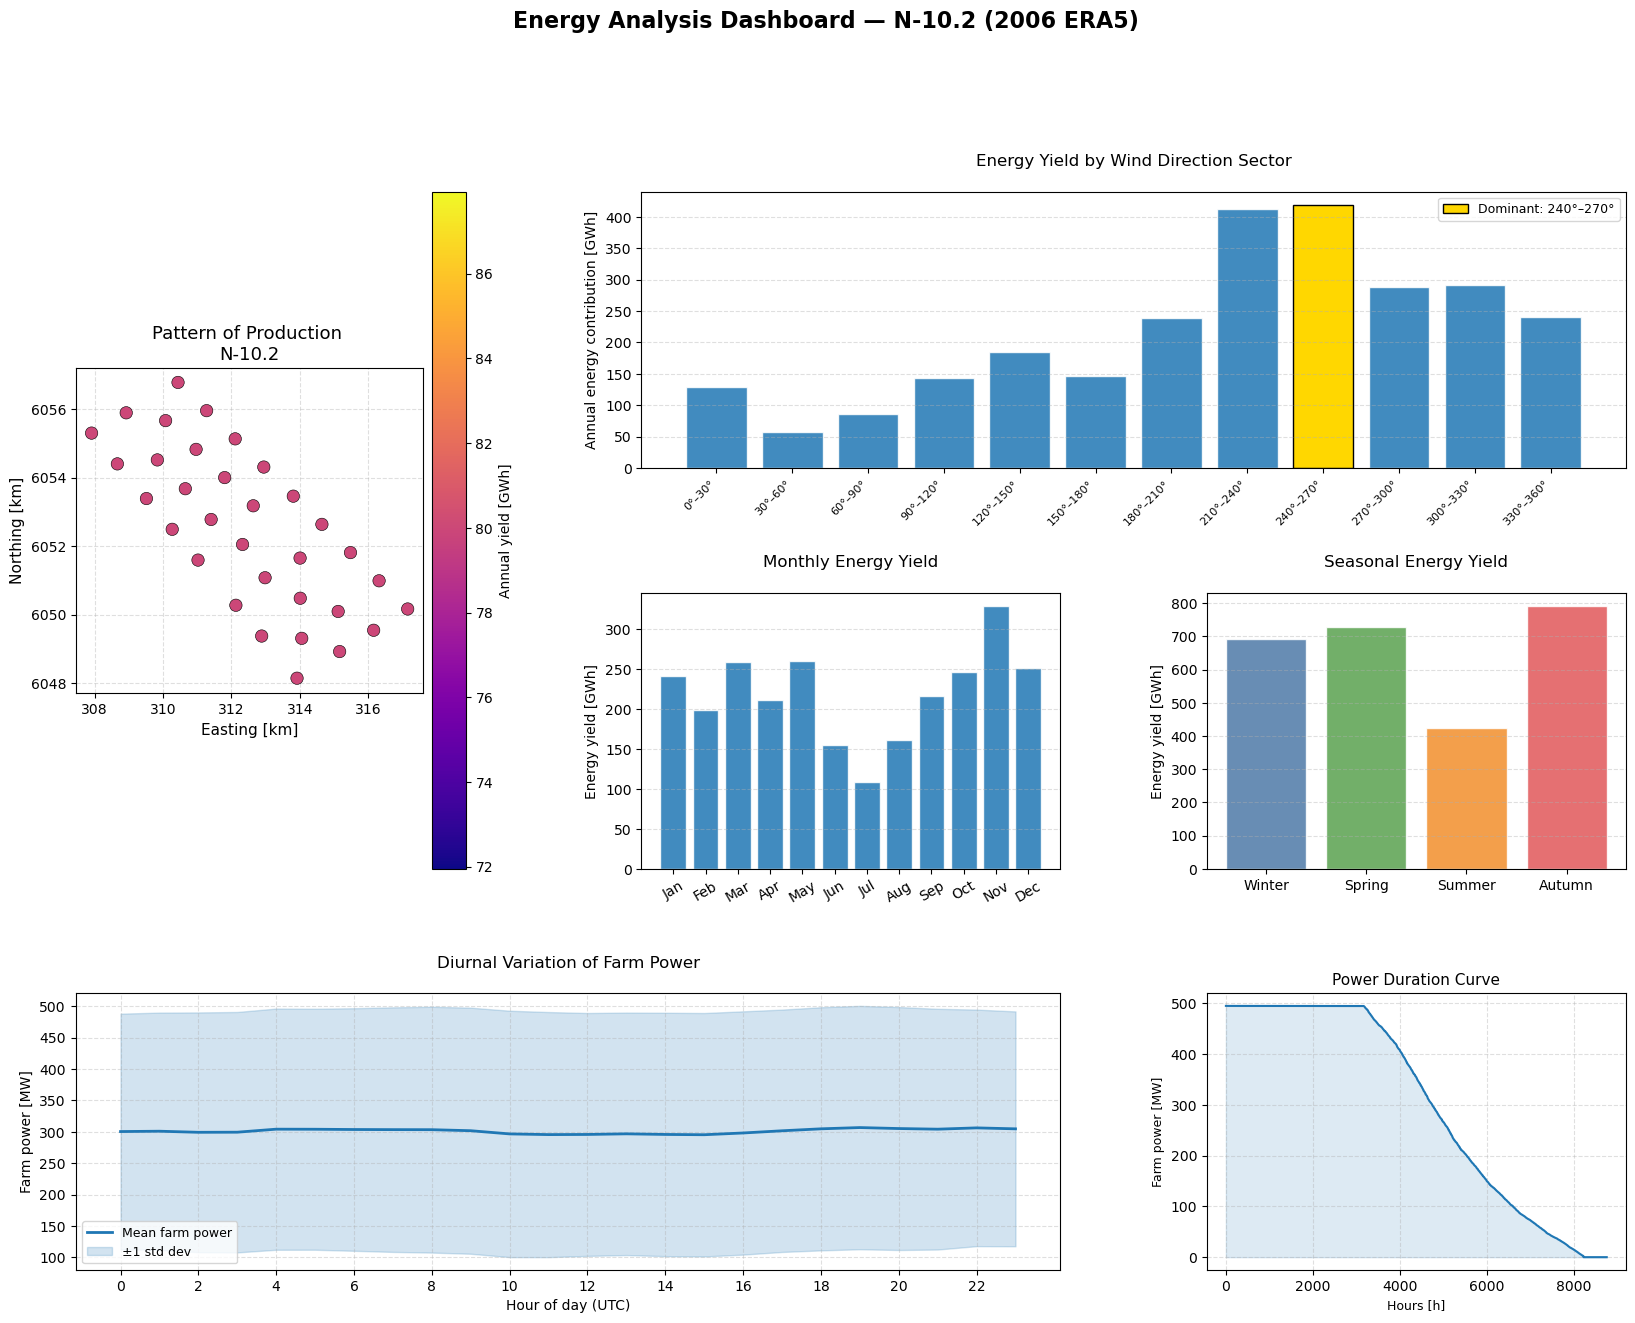

In [10]:
# ------------------------------------------------------------
# Layout paths
# ------------------------------------------------------------
farms = ["N-10.1", "N-10.2"]

layout_paths = {
    "N-10.1": Path("./turbine-info/area_of_interest/layout-N-10.1.geom.csv").resolve(strict=True),
    "N-10.2": Path("./turbine-info/area_of_interest/layout-N-10.2.geom.csv").resolve(strict=True),
}


for farm_name in farms:
    farm_layout = layout_paths[farm_name]
    results = compute_farm(farm_layout, states, mbook, farm_name)
    result_df = ta.prepare_results_df(results)
    ta.print_yield_summary(result_df, farm_name)
    ta.plot_full_dashboard(result_df, farm_name)

In [11]:
#ta.run_full_analysis(results1, results2)

# Task 4: Yield of the Area N-10 With External Wake Effects

We performed the calculations with external wake effects on the university's HPC cluster. The code used for that can be found in the files run_task4.py (actual python code that ran) and run_foxes.sh (slurm job submission script). We ran the code two times, once filtering out turbines that are further than 50km from any turbine in the N-10 area - and once keeping al provided turbines (practically we set the threshhold to 5000km, so that all turbines were included). The slurm output files are provided as 50km.out and all.out respectively.

## Excerpt from the slurm output files from HPC computations:

#### considering all 5143 turbines:

AOI mean power (with wakes) : 1196.6 MW <br>
AOI mean power (ambient/no wake): 1514.9 MW <br>
AOI efficiency   : 78.99 % <br>
AOI annual yield (with wakes)   : 10482.11 GWh <br>

#### considering 2014 turbines within 50km of AOI:

AOI mean power (with wakes) : 1208.1 MW <br>
AOI mean power (ambient/no wake): 1514.9 MW <br>
AOI efficiency   : 79.75 % <br>
AOI annual yield (with wakes)   : 10582.91 GWh <br>

Wake losses are 21.01 % considering all turbines vs. 20.25 % considering turbines within 50km.

# Task 5: External vs. Internal Wake Effects

Rerunning the same setup with only the turbines of the N-10 area tells us that this setup has wake losses of 14.14 %. This means that roughly 2/3 of the total wake losses come from internal wake effects.


  YIELD SUMMARY — N-10 (50km)
  Number of turbines      : 166
  Turbine yield (annual)  :
    Min  : 60.05 GWh
    Max  : 72.47 GWh
    Mean : 63.75 GWh
  Total farm yield/year   : 10582.91 GWh
  Mean farm power         : 1208.10 MW
  Rated capacity          : 2490 MW
  Capacity factor         : 48.5 %



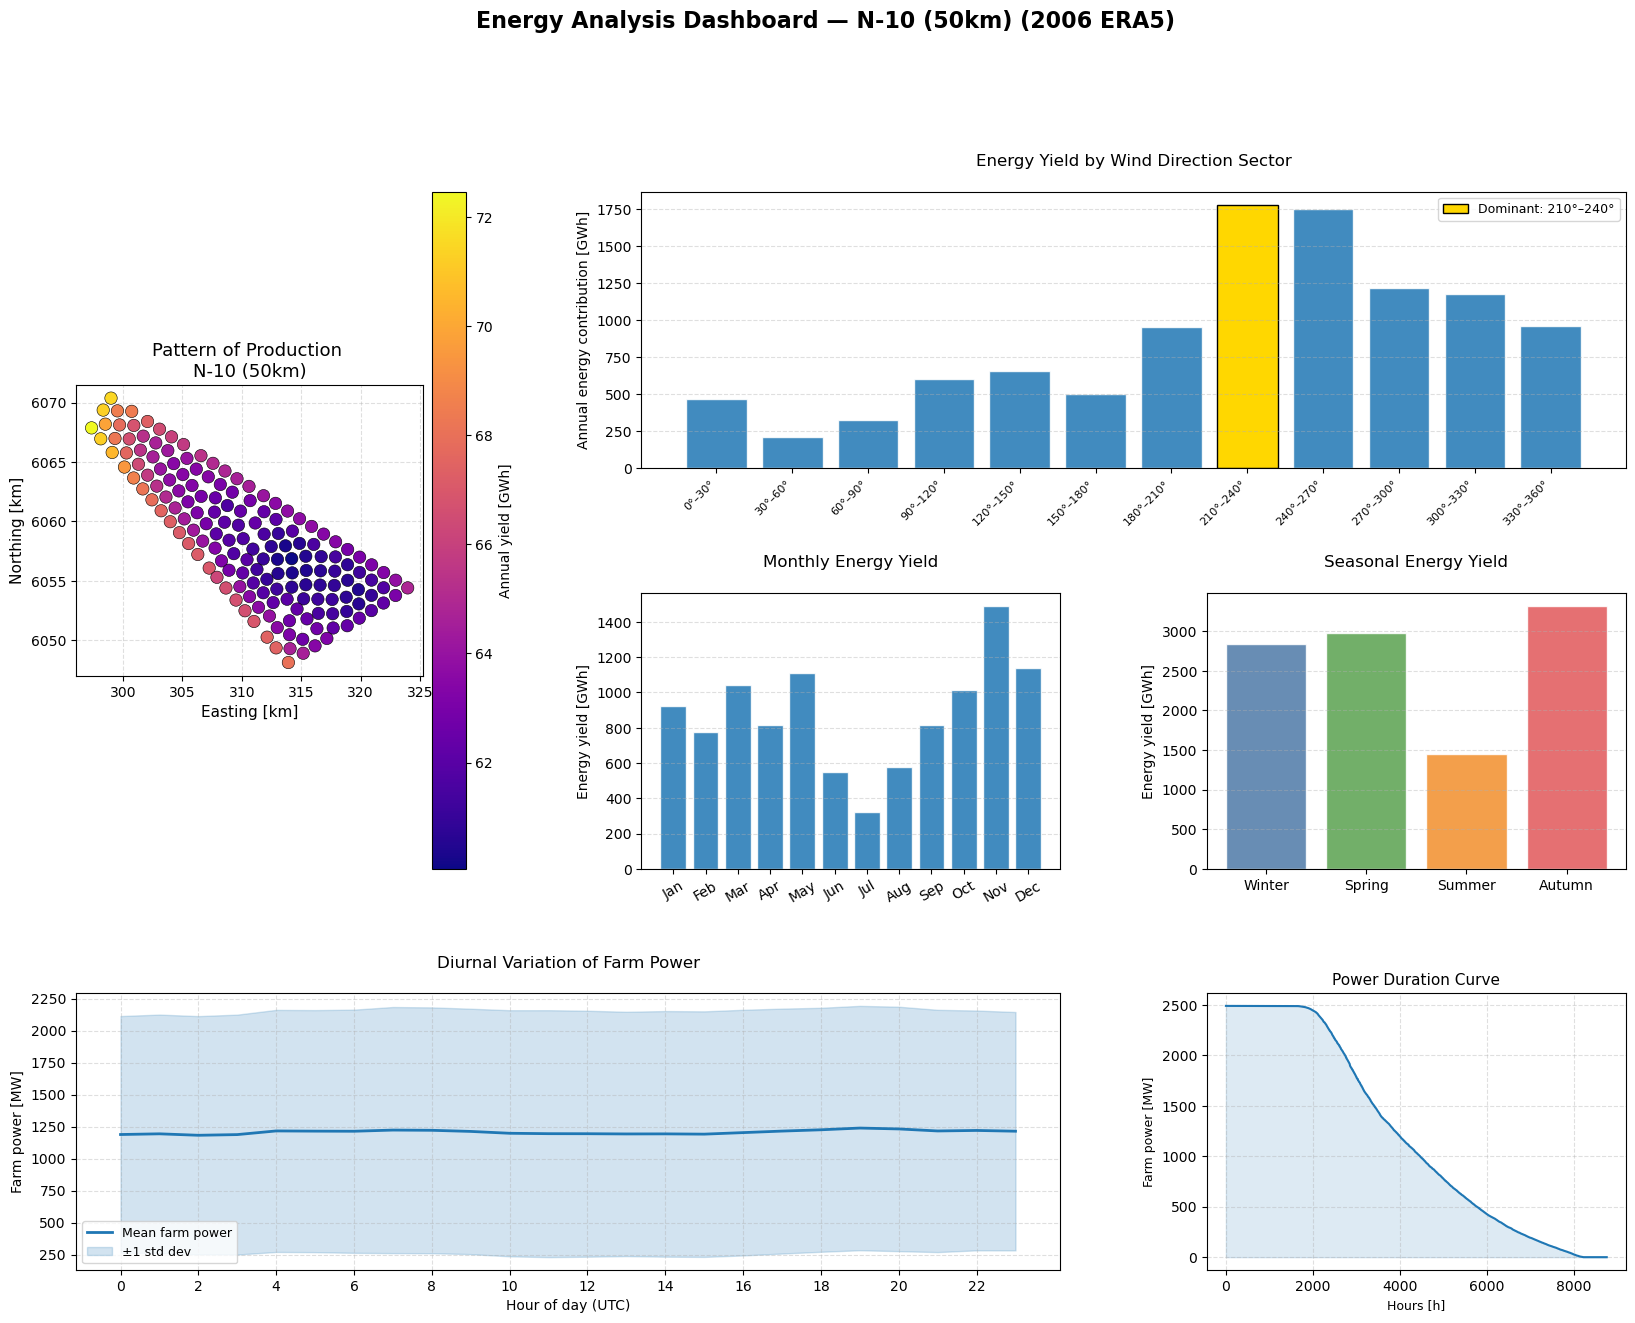


  YIELD SUMMARY — N-10 (full)
  Number of turbines      : 166
  Turbine yield (annual)  :
    Min  : 59.48 GWh
    Max  : 71.72 GWh
    Mean : 63.15 GWh
  Total farm yield/year   : 10482.11 GWh
  Mean farm power         : 1196.59 MW
  Rated capacity          : 2490 MW
  Capacity factor         : 48.1 %



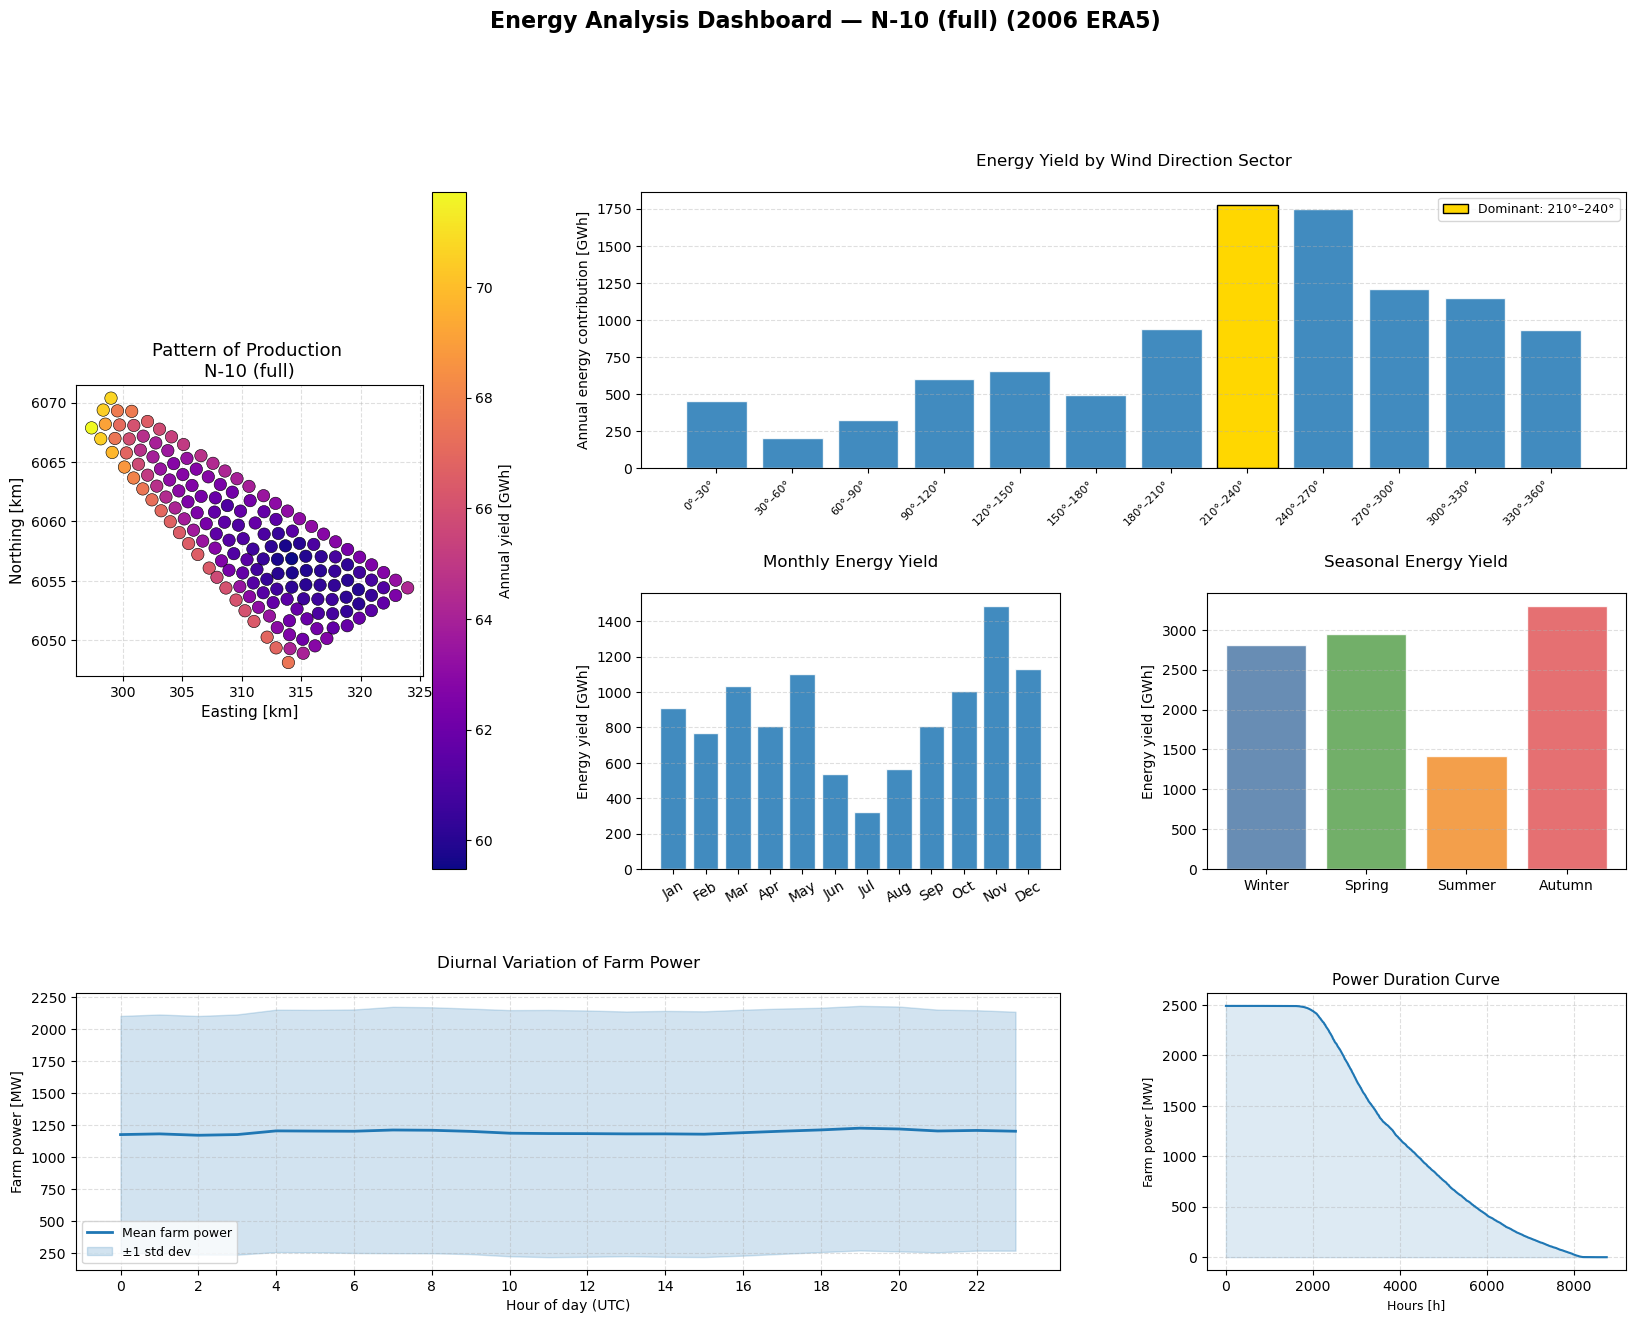

In [14]:
nc_paths = ["farm_results_50km.nc", "farm_results_all.nc"]
farm_name = "AOI"

farms = ["N-10 (50km)", "N-10 (full)"]

nc_paths = {
    "N-10 (50km)": Path("farm_results_50km.nc").resolve(strict=True),
    "N-10 (full)": Path("farm_results_all.nc").resolve(strict=True),
}

for farm_name in farms:
    result_df = ta.prepare_results_nc(nc_paths[farm_name])
    ta.print_yield_summary(result_df, farm_name)
    ta.plot_full_dashboard(result_df, farm_name)